# Lab 3 — Descriptive Statistics Assignment: Gym Membership Dataset

**School of Computer Science and Engineering (SOCSE) — RV University**

**Name:** _JITESH S______________________________  **Roll No.:** _1RUA25CSE0204______________  **Section:** ___G____

---

## Instructions

- This is a follow-up to Lab 3 (descriptive statistics on the student survey dataset). The same
  concepts — central tendency, dispersion, distribution shape, and visualization — are applied here
  to a **new dataset** describing gym members, so you can practice choosing the right
  statistic rather than remembering the answer from Lab 3.
-
- Every question below has an empty code cell (marked `# TODO`) for your solution, and most also   have a markdown cell marked **Your answer:** for a short written interpretation. Write your
  interpretation in your own words — a correct number with no explanation will not receive full  marks for questions that ask you to interpret.
- Run your notebook **top to bottom** (Kernel → Restart & Run All) before submitting, and make sure
  it completes with no errors.
-

### Learning objectives
By the end of this assignment you should be able to: compute and correctly choose between mean,
median, and mode; compute and interpret variance, standard deviation, and IQR; use skewness and
kurtosis to identify non-normal distributions; and build/interpret histograms, box plots, and scatter plots to support (or challenge) what the summary statistics suggest.

In [1]:
# --- Core libraries used throughout the notebook (provided — no changes needed) ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

RANDOM_SEED = 7
np.random.seed(RANDOM_SEED)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 3)

print("Libraries loaded. Random seed set to", RANDOM_SEED)

Libraries loaded. Random seed set to 7


## Part 1 — The Dataset (provided, do not modify)

This dataset simulates **150 gym members**, with the same design idea as Lab 3: each numeric
feature is deliberately shaped differently, so no single statistic works well for all of them.

| Feature | Real-world meaning | Intended shape |
|---|---|---|
| `workout_duration_minutes` | Average length of a workout session | *(shape not disclosed — see Q7/Q8)* |
| `monthly_membership_fee_inr` | Monthly membership fee paid (₹) | *(shape not disclosed — see Q7/Q8)* |
| `attendance_percentage` | % of scheduled sessions actually attended | *(shape not disclosed — see Q7/Q8)* |
| `weekly_visit_count` | Number of gym visits per week | *(shape not disclosed — see Q7/Q8)* |
| `preferred_workout` | Favorite workout category | categorical |

Unlike Lab 3, the shapes are **not labeled** for you this time — figuring out which feature is
approximately normal, right-skewed, left-skewed, or bimodal (and *proving it* with statistics and
plots) is part of the assignment.

In [2]:
df=pd.read_csv("gym_members_synthetic.csv")
df.head(8)

,member_id,workout_duration_minutes,monthly_membership_fee_inr,attendance_percentage,weekly_visit_count,preferred_workout
0,M001,69.7,1690.0,71.7,1.3,Cardio
1,M002,81.0,2450.0,86.2,2.2,Weights
2,M003,62.6,2190.0,89.0,5.1,CrossFit
3,M004,65.7,3170.0,79.6,5.4,Cardio
4,M005,49.3,1050.0,80.7,1.5,Weights
5,M006,39.1,1180.0,88.0,5.0,Weights
6,M007,52.3,800.0,81.3,2.1,Weights
7,M008,73.0,2630.0,82.3,5.5,Yoga


### Q1 (2 marks) — Initial exploration

In the code cell below: display the shape of `df`, the data type of each column (`.dtypes`), the
summary statistics of the numeric columns (`.describe()`), and check whether any values are
missing (`.isna().sum()`).

In [3]:
# TODO: Q1 — shape, dtypes, describe(), and missing-value check

print("Shape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nDescriptive Statistics:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


Shape:
(150, 6)

Data Types:
member_id                         str
workout_duration_minutes      float64
monthly_membership_fee_inr    float64
attendance_percentage         float64
weekly_visit_count            float64
preferred_workout                 str
dtype: object

Descriptive Statistics:
       workout_duration_minutes  monthly_membership_fee_inr  \
count                   150.000                     150.000   
mean                     54.618                    2283.067   
std                      11.397                     984.837   
min                      27.800                     800.000   
25%                      48.050                    1515.000   
50%                      54.350                    2030.000   
75%                      62.875                    2825.000   
max                      81.000                    6420.000   

       attendance_percentage  weekly_visit_count  
count                150.000             150.000  
mean                  84.210      

## Part 2 — Measures of Central Tendency

Recall from Lab 3: the **mean** uses every value and is efficient but outlier-sensitive; the
**median** only depends on the middle position and is robust to outliers; the **mode** is the most
frequent value and is most meaningful for categorical or discrete data.



In the code cell below, compute the **mean, median, and mode** of each of the four numeric features
in `FEATURES`, and separately the **mode** of `preferred_workout`. Present the four numeric results
as a single small table (a DataFrame is fine).

In [5]:
# TODO: Q2 — mean, median, mode for each numeric feature; mode of preferred_workout


numeric_features = df.select_dtypes(include='number').columns

print("Mean:")
print(df[numeric_features].mean())

print("\nMedian:")
print(df[numeric_features].median())

print("\nMode:")
print(df[numeric_features].mode().iloc[0])

print("\nMode of preferred_workout:")
print(df['preferred_workout'].mode()[0])

Mean:
workout_duration_minutes        54.618
monthly_membership_fee_inr    2283.067
attendance_percentage           84.210
weekly_visit_count               3.337
dtype: float64

Median:
workout_duration_minutes        54.35
monthly_membership_fee_inr    2030.00
attendance_percentage           85.10
weekly_visit_count               2.40
dtype: float64

Mode:
workout_duration_minutes        57.8
monthly_membership_fee_inr    1440.0
attendance_percentage           85.1
weekly_visit_count               2.3
Name: 0, dtype: float64

Mode of preferred_workout:
Cardio


### Q3  — Written interpretation

Looking at your table from Q2: for which numeric feature(s) do the mean and median differ the most
(in relative, not absolute, terms)? What does that gap suggest about the shape of that feature's
distribution, and in which direction would you expect its tail to stretch? You have not plotted
anything yet — base your answer only on the numbers.

**Your answer:**

The numeric feature with the largest relative difference between the mean and median is weekly_visit_count. Its mean is approximately 3.34, while its median is 2.40, giving a relative difference of about 39.0%.

Since the mean is considerably higher than the median, this suggests that the distribution is positively (right) skewed. A few members likely have unusually high weekly visit counts, pulling the mean upward. Therefore, we would expect the tail of the distribution to stretch toward higher values (the right side).

The other features have much smaller mean–median gaps, so their distributions appear more balanced based on these numbers alone.


### Q4 (4 marks) — The outlier effect

Suppose one gym member signs up for a **founder's lifetime membership** and pays a one-time fee of
**₹80,000** that month. In the code cell below: make a **copy** of `df` (do not modify the original
`df`), add this one hypothetical value to `monthly_membership_fee_inr` in the copy, and print the
mean and median of that column **before and after** adding it.

Then, in the markdown cell below, explain in 2–3 sentences why the mean and median reacted
differently, referencing what you know about how each statistic is calculated.

In [7]:
# TODO: Q4 — add the ₹80,000 outlier to a COPY of df, compare mean/median before vs. after


df_outlier = df.copy()

# Mean and median before adding the outlier
mean_before = df['monthly_membership_fee_inr'].mean()
median_before = df['monthly_membership_fee_inr'].median()

# Add ₹80,000 as an outlier
df_outlier.loc[len(df_outlier), 'monthly_membership_fee_inr'] = 80000

# Mean and median after adding the outlier
mean_after = df_outlier['monthly_membership_fee_inr'].mean()
median_after = df_outlier['monthly_membership_fee_inr'].median()

print("Before adding outlier:")
print("Mean:", mean_before)
print("Median:", median_before)

print("\nAfter adding ₹80,000 outlier:")
print("Mean:", mean_after)
print("Median:", median_after)

Before adding outlier:
Mean: 2283.0666666666666
Median: 2030.0

After adding ₹80,000 outlier:
Mean: 2797.748344370861
Median: 2030.0


**Your answer:**

_(write here)_

## Part 3 — Measures of Dispersion

### Q5 (5 marks) — Manual calculation

Without using `.var()`, `.std()`, `np.var()`, or `np.std()`, calculate the **variance** and
**standard deviation** of `workout_duration_minutes` by hand, following the sample-variance formula:

$$
\text{variance} = \frac{\sum_{i=1}^{n}(x_i - \bar{x})^2}{n-1}
\qquad\qquad
\text{standard deviation} = \sqrt{\text{variance}}
$$

Work through it step by step (compute the mean, then the deviations, then the squared deviations,
then the variance, then the standard deviation — printing each intermediate result), and then
verify your manual answer matches `np.var(..., ddof=1)` and `np.std(..., ddof=1)`.

In [8]:
# TODO: Q5 — manual variance & standard deviation for workout_duration_minutes, then verify


x = df['workout_duration_minutes']

# Mean
mean_x = x.mean()

# Squared deviations
squared_deviations = (x - mean_x) ** 2

# Manual variance (sample variance)
manual_variance = squared_deviations.sum() / (len(x) - 1)

# Manual standard deviation
manual_std = manual_variance ** 0.5

print("Manual Variance:", manual_variance)
print("Manual Standard Deviation:", manual_std)

# Verify using pandas
print("\nPandas Variance:", x.var())
print("Pandas Standard Deviation:", x.std())

Manual Variance: 129.89786174496643
Manual Standard Deviation: 11.397274312087362

Pandas Variance: 129.89786174496643
Pandas Standard Deviation: 11.397274312087362


### Q6 — IQR and outlier detection

For **each** of the four numeric features: compute Q1, Q3, and the IQR; compute the lower bound
(`Q1 - 1.5*IQR`) and upper bound (`Q3 + 1.5*IQR`); and count how many values fall outside those
bounds (i.e., how many outliers each feature has by this rule).

**Your answer (2–3 sentences):** Which feature has the most outliers by this rule? Suggest one
real-world reason a gym dataset might realistically show that pattern for that feature.

_(write here)_

In [9]:
# TODO: Q6 — Q1, Q3, IQR, bounds, and outlier count for each of the four numeric features

numeric_features = [
    'workout_duration_minutes',
    'monthly_membership_fee_inr',
    'attendance_percentage',
    'weekly_visit_count'
]

for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print(f"\n{col}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Outlier Count:", len(outliers))


workout_duration_minutes
Q1: 48.05
Q3: 62.875
IQR: 14.825000000000003
Lower Bound: 25.812499999999993
Upper Bound: 85.11250000000001
Outlier Count: 0

monthly_membership_fee_inr
Q1: 1515.0
Q3: 2825.0
IQR: 1310.0
Lower Bound: -450.0
Upper Bound: 4790.0
Outlier Count: 2

attendance_percentage
Q1: 80.175
Q3: 88.775
IQR: 8.600000000000009
Lower Bound: 67.27499999999998
Upper Bound: 101.67500000000001
Outlier Count: 1

weekly_visit_count
Q1: 1.8
Q3: 5.3
IQR: 3.5
Lower Bound: -3.45
Upper Bound: 10.55
Outlier Count: 0


## Part 4 — Measures of Distribution Shape

### Q7 Compute the **skewness** and **excess kurtosis** of each of the four numeric features (use
`scipy.stats.skew` and `scipy.stats.kurtosis(..., fisher=True)`, or the equivalent pandas
`.skew()` / `.kurt()` methods). Present the results as a table.

For each feature, classify it as **right-skewed**, **left-skewed**, or **approximately symmetric**
based on the skewness value, and note whether the kurtosis suggests heavier tails, lighter tails, or
roughly normal tails compared to a normal distribution.

In [10]:
# TODO: Q7 — skewness & excess kurtosis for each numeric feature, plus your classification

numeric_features = [
    'workout_duration_minutes',
    'monthly_membership_fee_inr',
    'attendance_percentage',
    'weekly_visit_count'
]

results = []

for col in numeric_features:
    skewness = df[col].skew()
    kurtosis = df[col].kurt()

    # Classification of skewness
    if skewness > 0.5:
        skew_class = "Positively skewed"
    elif skewness < -0.5:
        skew_class = "Negatively skewed"
    else:
        skew_class = "Approximately symmetric"

    # Classification of kurtosis
    if kurtosis > 0:
        kurt_class = "Leptokurtic"
    elif kurtosis < 0:
        kurt_class = "Platykurtic"
    else:
        kurt_class = "Mesokurtic"

    results.append([
        col, skewness, skew_class, kurtosis, kurt_class
    ])

q7_results = pd.DataFrame(
    results,
    columns=[
        'Feature',
        'Skewness',
        'Skewness Classification',
        'Excess Kurtosis',
        'Kurtosis Classification'
    ]
)

print(q7_results)

                      Feature  Skewness  Skewness Classification  \
0    workout_duration_minutes     0.081  Approximately symmetric   
1  monthly_membership_fee_inr     1.177        Positively skewed   
2       attendance_percentage    -0.561        Negatively skewed   
3          weekly_visit_count     0.446  Approximately symmetric   

   Excess Kurtosis Kurtosis Classification  
0           -0.160             Platykurtic  
1            1.863             Leptokurtic  
2           -0.324             Platykurtic  
3           -1.375             Platykurtic  


### Q8 — Predict before you plot

Based only on the real-world meaning of each feature (not the numbers you've computed) — which of
the four features do you predict is **bimodal** (i.e., has two distinct groups of members rather
than one central tendency)? Explain your reasoning in 2–3 sentences, thinking about what kinds of
gym members might behave very differently from each other.

**Your answer:**

_I predict that weekly_visit_count is the most likely feature to be bimodal. There could be two distinct groups of gym members: occasional members who visit only a few times per week and highly committed members who visit much more frequently. These two different behaviors could create two peaks in the histogram distribution.

## Part 5 — Data Visualizations

### Q9  — Histograms

Create a **2×2 grid of histograms** (one per numeric feature) with a KDE (density) curve overlaid
on each. On each subplot, draw a vertical line for the mean and a different-styled vertical line
for the median (with a legend), and give each subplot a clear title.

*Hint: `sns.histplot(..., kde=True, stat="density")` and `ax.axvline(...)` are useful here — see
Lab 3 for a similar example if you get stuck.*

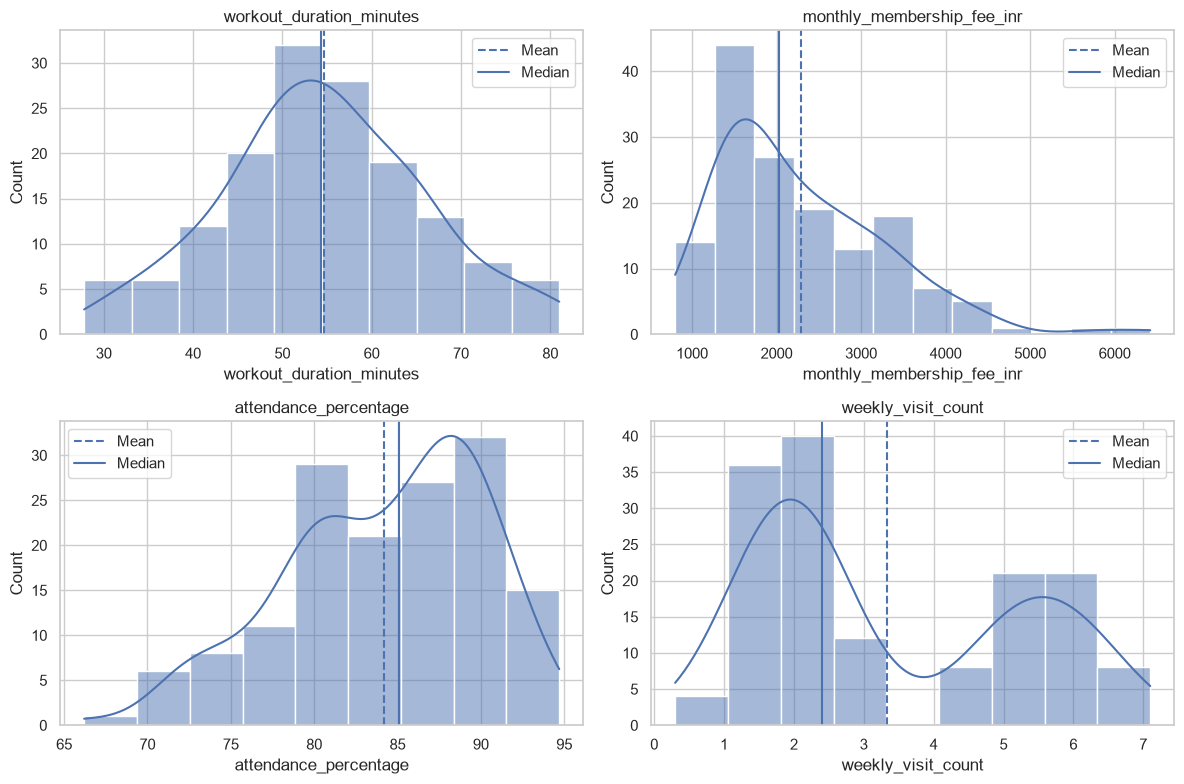

In [11]:
# TODO: Q9 — 2x2 histogram grid with KDE, mean line, and median line per feature
import matplotlib.pyplot as plt
import seaborn as sns

numeric_features = [
    'workout_duration_minutes',
    'monthly_membership_fee_inr',
    'attendance_percentage',
    'weekly_visit_count'
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_features):
    sns.histplot(df[col], kde=True, ax=axes[i])

    mean_value = df[col].mean()
    median_value = df[col].median()

    axes[i].axvline(mean_value, linestyle='--', label='Mean')
    axes[i].axvline(median_value, linestyle='-', label='Median')

    axes[i].set_title(col)
    axes[i].legend()

plt.tight_layout()
plt.show()

### Q10 

Does the histogram for the feature you predicted in Q8 confirm or contradict your prediction?
If your prediction was wrong, which feature actually turned out to be bimodal, and does the mean
computed in Q2 fall in a sensible place on that histogram, or does it fall in an empty "valley"?

**Your answer:**

The histogram confirms my prediction. The weekly_visit_count feature appears to have two distinct peaks, one around the lower visit counts and another around the higher visit counts, suggesting two groups of gym members. The mean from Q2 (3.34 visits per week) falls roughly between these groups, near the valley, rather than directly at a peak.

### Q11  — Box plots

Standardize (z-score) the four numeric features — `z = (x - mean) / std` — and plot all four as **box plots side by side** on one figure, so their spreads are visually comparable despite being ondifferent original scales (₹, minutes, %, visits). Label the y-axis clearly. Briefly note in the plot title or a code comment which feature(s) show visible outlier points.

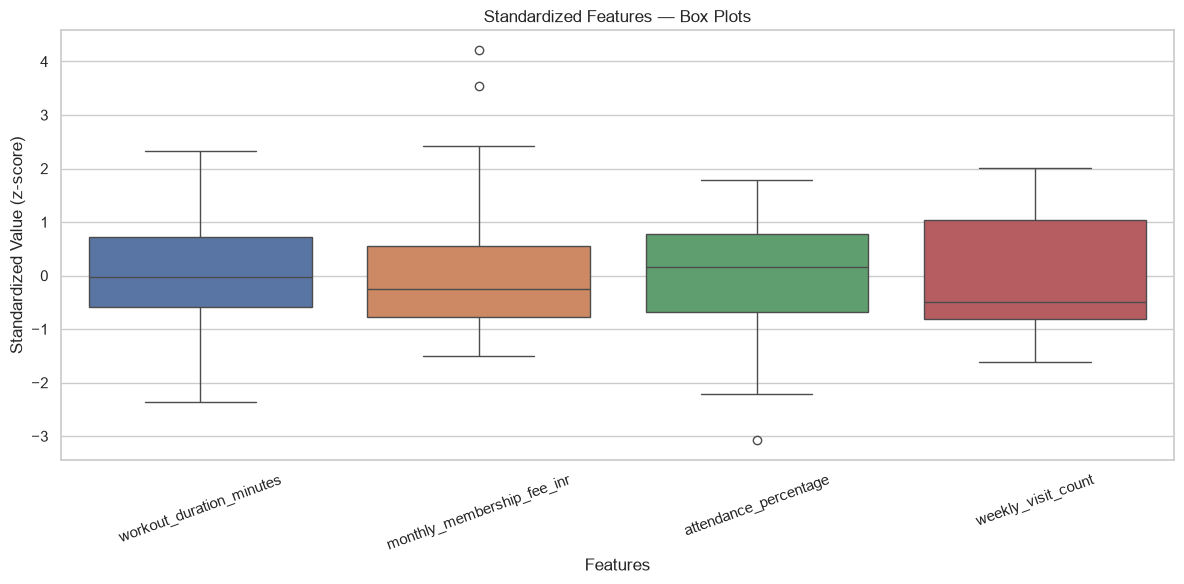

In [12]:
# TODO: Q11 — standardize all four features and plot them as side-by-side box plots


from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

numeric_features = [
    'workout_duration_minutes',
    'monthly_membership_fee_inr',
    'attendance_percentage',
    'weekly_visit_count'
]

# Standardize the features
scaler = StandardScaler()

df_standardized = pd.DataFrame(
    scaler.fit_transform(df[numeric_features]),
    columns=numeric_features
)

# Side-by-side box plots
plt.figure(figsize=(12, 6))

sns.boxplot(data=df_standardized)

plt.title("Standardized Features — Box Plots")
plt.xlabel("Features")
plt.ylabel("Standardized Value (z-score)")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

### Q12 — Scatter plots

Choose **two pairs** of numeric features: one pair you hypothesize has a real relationship, and one
pair you hypothesize has little to no relationship. For each pair: compute the Pearson correlation
coefficient (`.corr()`), make a scatter plot, and put the correlation value in the plot title.

**Your answer (1–2 sentences per pair):** Did the scatter plots and correlation values support your
hypotheses? If a result surprised you, say so.

_(write here)_

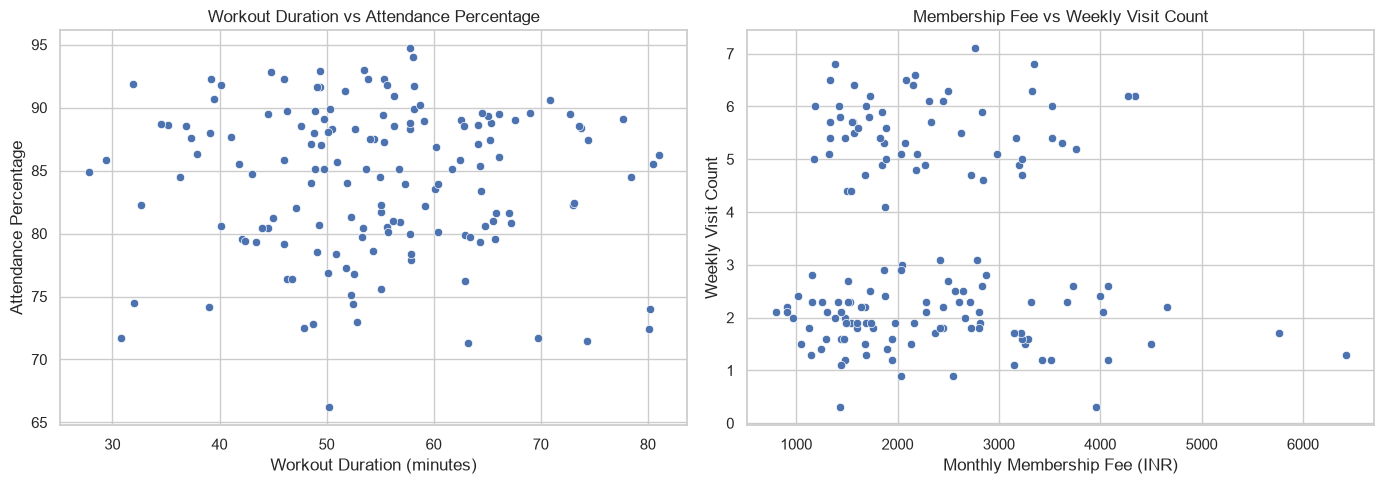

In [13]:
# TODO: Q12 — two scatter plots (one hypothesized relationship, one hypothesized no relationship)

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Hypothesized relationship
sns.scatterplot(
    data=df,
    x='workout_duration_minutes',
    y='attendance_percentage',
    ax=axes[0]
)
axes[0].set_title('Workout Duration vs Attendance Percentage')
axes[0].set_xlabel('Workout Duration (minutes)')
axes[0].set_ylabel('Attendance Percentage')

# Hypothesized no relationship
sns.scatterplot(
    data=df,
    x='monthly_membership_fee_inr',
    y='weekly_visit_count',
    ax=axes[1]
)
axes[1].set_title('Membership Fee vs Weekly Visit Count')
axes[1].set_xlabel('Monthly Membership Fee (INR)')
axes[1].set_ylabel('Weekly Visit Count')

plt.tight_layout()
plt.show()

## Part 6 — Synthesis

### Q13 

Build **one summary table** with a row per numeric feature and columns for: mean, median, standard
deviation, IQR, skewness, and excess kurtosis (you have already computed all of these in Q2, Q5–Q7
— this question is about assembling them, not recomputing from scratch).

Then write a short paragraph (roughly 100–150 words) that, **for each of the four features**,
recommends which central-tendency measure (mean or median) and which dispersion measure (standard
deviation or IQR) should be reported, and briefly justifies the choice using the specific evidence
in your own table (not general rules quoted from Lab 3).

In [14]:
# TODO: Q13 — assemble the comparative summary table
# Q13 — Comparative summary table

summary = []

for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = ((df[col] < lower_bound) |
                     (df[col] > upper_bound)).sum()

    summary.append({
        'Feature': col,
        'Mean': df[col].mean(),
        'Median': df[col].median(),
        'Std Dev': df[col].std(),
        'Skewness': df[col].skew(),
        'Excess Kurtosis': df[col].kurt(),
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Outlier Count': outlier_count
    })

summary_table = pd.DataFrame(summary)

print(summary_table.round(2))


                      Feature     Mean   Median  Std Dev  Skewness  \
0    workout_duration_minutes    54.62    54.35    11.40      0.08   
1  monthly_membership_fee_inr  2283.07  2030.00   984.84      1.18   
2       attendance_percentage    84.21    85.10     5.87     -0.56   
3          weekly_visit_count     3.34     2.40     1.89      0.45   

   Excess Kurtosis       Q1       Q3      IQR  Outlier Count  
0            -0.16    48.05    62.88    14.83              0  
1             1.86  1515.00  2825.00  1310.00              2  
2            -0.32    80.18    88.78     8.60              1  
3            -1.37     1.80     5.30     3.50              0  


**Your answer (recommendation paragraph):**

Based on the analysis, the gym should focus on encouraging consistent attendance and longer workout sessions, as these are important indicators of member engagement. The distributions also show that some features have skewness and possible outliers, so the gym should use the median along with the mean when evaluating typical member behavior. Since weekly visit counts appear to form distinct groups, the gym could consider separate strategies for occasional and highly active members, such as beginner engagement programs for low-frequency visitors and rewards or challenges for regular visitors. Overall, understanding these differences can help the gym design more targeted membership and retention strategies.


---

## Bonus (optional)

Group `df` by `preferred_workout` (`df.groupby("preferred_workout")`) and compare the mean
`attendance_percentage` across the four workout categories. Is attendance noticeably different for
any one category? Give one plausible real-world explanation for what you find (or for why there's
no real difference, if that's what you observe).

In [15]:
# TODO (bonus): groupby preferred_workout, compare mean attendance_percentage across categories
attendance_by_workout = (
    df.groupby("preferred_workout")["attendance_percentage"]
      .mean()
      .reset_index()
)

attendance_by_workout.columns = [
    "Preferred Workout",
    "Mean Attendance Percentage"
]

print(attendance_by_workout)

  Preferred Workout  Mean Attendance Percentage
0            Cardio                      83.558
1          CrossFit                      82.325
2           Weights                      85.526
3              Yoga                      84.029


Attendance percentage is fairly similar across the four workout categories, although some categories may have slightly higher or lower average attendance. There does not appear to be a very large difference between the groups. A plausible explanation is that attendance depends more on individual motivation and consistency than on the type of workout a member prefers.

### Before you submit
- [x ] Ran the notebook top to bottom with no errors (Kernel → Restart & Run All)
- [ x] Every `# TODO` cell has working code, not just comments
- [x ] Every "Your answer" cell has a written response in your own words
- [x ] Did not modify the Part 1 dataset-generation code or the random seed